# Case file 6 · The Whole Canvas: train your own sprite model

<a href="https://colab.research.google.com/github/umanets/pixelsprite/blob/main/learn/06_mini_canvas.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The real model: 39 million parameters, 1.4 million sprites, 6 hours on a big rented GPU.
Yours: the **same architecture class** (`pixelsprite.CanvasGPT2`), shrunk to about 1 million parameters,
30,000 sprites, a 64-colour palette, and 8 minutes. It will not be as good, but every step is the real one:
palette → tokens → teacher forcing → loss in bits → sampling with guidance.

**Time:** about 10 minutes on a laptop CPU; on a Colab GPU (Runtime → Change runtime type → T4) it trains
several times more steps in the same time.

In [1]:
try:
    import pixelsprite
except ImportError:
    %pip -q install "pixelsprite[learn] @ git+https://github.com/umanets/pixelsprite"
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
import math, time
import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from pixelsprite import CanvasConfig, CanvasGPT2, sample, sheet, rgba_from_index
from pixelsprite.colour import nearest_index, srgb_to_oklab
from pixelsprite.data import load_shard
from pixelsprite.model import edge_flags
from pixelsprite.text import TextEncoder

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
TRAIN_SECONDS = 480                     # change me
K = 64                                  # palette size
print("device:", device)

device: cpu


## 1. Palette and tokens
Every pixel becomes one token: a palette index 0…63, or **EMPTY** (= 64) for a transparent pixel. So a sprite is
256 tokens, and "transparent" is just one more colour. This trick lets one model decide shape and colour together.

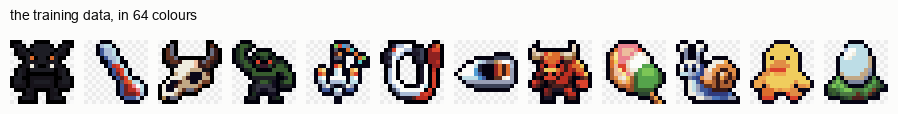

In [3]:
data = load_shard(n=30000, seed=2)
solid = data.rgba[data.mask][:, :3]
colours, counts = np.unique(solid, axis=0, return_counts=True)
lab = torch.as_tensor(srgb_to_oklab(colours)); w = torch.as_tensor(counts, dtype=torch.float64)
centres = lab[torch.multinomial(w, K, generator=torch.Generator().manual_seed(0))].clone()
for _ in range(30):                                                   # k-means in OKLab, as in case file 5
    owner = torch.cdist(lab, centres).argmin(1)
    for k in range(K):
        if (owner == k).any():
            centres[k] = (lab[owner == k] * w[owner == k, None]).sum(0) / w[owner == k].sum()
palette = colours[torch.cdist(centres, lab).argmin(1).numpy()]       # nearest real colour to each centre
index = np.where(data.mask, nearest_index(data.rgba[..., :3], palette), -1)        # (N, 16, 16), -1 = EMPTY
display(sheet([rgba_from_index(x, palette) for x in index[:12]], "the training data, in 64 colours", scale=4, cols=12))

In [4]:
encoder = TextEncoder()
uniq = sorted(set(data.subject))
vec = dict(zip(uniq, encoder(uniq)))
text = torch.stack([vec[s] for s in data.subject])
tokens = torch.as_tensor(np.where(index < 0, K, index).reshape(len(index), 256))  # EMPTY = K
n_val = 1000

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4381.66it/s]

## 2. The model: the real class, small settings

In [5]:
cfg = CanvasConfig(n_colors=K, d_model=128, n_layers=4, n_heads=4, d_ff=512, dropout=0.0, max_size=16, sizes=(16,))
model = CanvasGPT2(cfg).to(device)
print(f"{model.n_params():,} parameters (the real one has 39,134,721)")

ar = torch.arange(256, device=device)
ROWS, COLS = (ar // 16)[None], (ar % 16)[None]

def loss_on(idx, drop_text=0.1):
    """Teacher forcing: show the model the true previous pixels, score its guess for every next pixel at once."""
    tgt = tokens[idx].to(device)
    b = len(idx)
    prev = torch.cat([torch.full((b, 1), model.BOS, device=device), tgt[:, :-1]], 1)
    known = torch.zeros(b, dtype=torch.bool, device=device)                       # no silhouette given
    mask = torch.zeros(b, 16, 16, dtype=torch.bool, device=device)
    drop = torch.rand(b, device=device) < drop_text
    cond = model.cond(text[idx].to(device), drop=drop)
    logits = model(cond, 16, mask, known, prev, ROWS.expand(b, -1), COLS.expand(b, -1), edge_flags(mask, known))
    return F.cross_entropy(logits.float().reshape(-1, K + 1), tgt.reshape(-1))

867,265 parameters (the real one has 39,134,721)


## 3. Train against the clock

959 steps in 480s, validation 415 bits per sprite


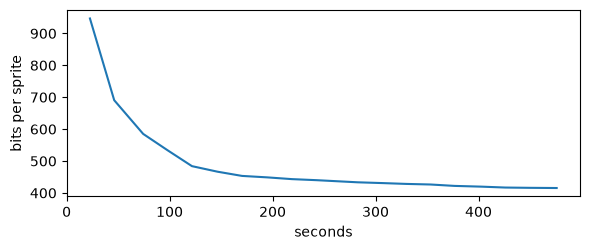

In [6]:
opt = torch.optim.AdamW(model.parameters(), lr=1.5e-3, betas=(0.9, 0.95), weight_decay=0.05)
use_amp = device == "cuda"
scaler = torch.amp.GradScaler(enabled=use_amp)
train_idx, val_idx = np.arange(n_val, len(tokens)), torch.arange(n_val)
history, t0, step = [], time.time(), 0
model.train()
while time.time() - t0 < TRAIN_SECONDS:
    idx = torch.as_tensor(np.random.choice(train_idx, 48))
    with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
        loss = loss_on(idx)
    opt.zero_grad()
    scaler.scale(loss).backward()
    scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update(); step += 1
    if step % 50 == 0:
        model.eval()
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            val = loss_on(val_idx[:256], drop_text=0).item()
        model.train()
        history.append((time.time() - t0, val * 256 / math.log(2)))
print(f"{step} steps in {time.time() - t0:.0f}s, validation {history[-1][1]:.0f} bits per sprite")
plt.figure(figsize=(6, 2.6)); plt.plot(*zip(*history)); plt.xlabel("seconds"); plt.ylabel("bits per sprite"); plt.tight_layout(); plt.show()

## 4. Draw with the library's sampler
`pixelsprite.sample` is the code the real model uses: one pixel at a time with a key/value cache, separate
guidance for shape (`g_shape`) and colour (`g_colour`), and a filter that redraws sprites with stray specks.

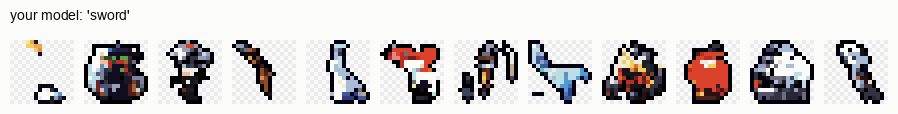

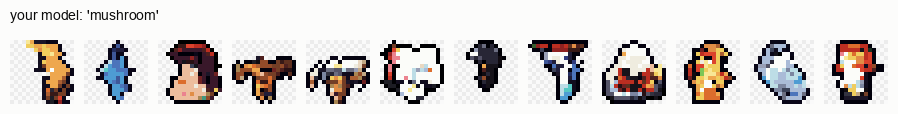

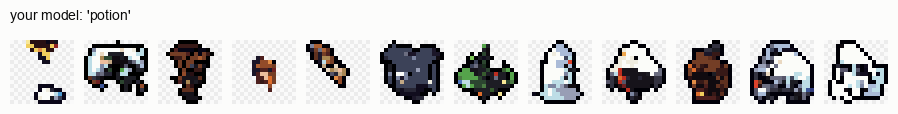

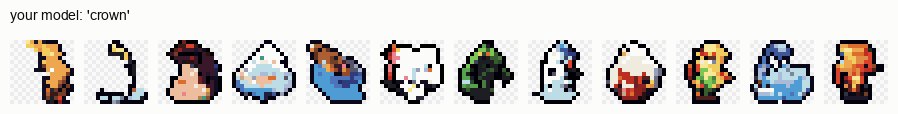

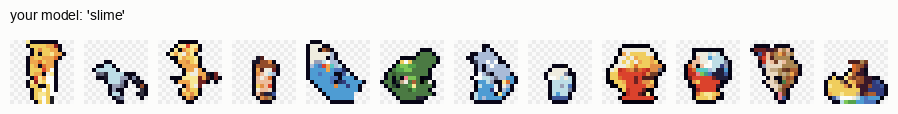

In [7]:
model.eval()
for caption in ["sword", "mushroom", "potion", "crown", "slime"]:
    idx, stats = sample(model, 12, encoder([caption]), size=16, g_shape=1.0, g_colour=2.0, seed=0, chunk=12)
    display(sheet([rgba_from_index(x, palette) for x in idx], f"your model: '{caption}'", scale=4, cols=12))

## Your turn
1. Train longer (`TRAIN_SECONDS = 1800`) or on a GPU and compare the bits and the pictures.
2. Change `g_shape` to 2 and 3. What happens to the variety of shapes?
3. Save your model with `torch.save(model.state_dict(), "my_model.pt")`, so you can keep drawing later.